In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path ="all_data_M_2023.xlsx"
df = pd.read_excel(file_path, sheet_name = "All May 2023 data")
df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [3]:
print(df.shape)

(413327, 32)


In [4]:
print(df.columns.tolist())

['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


In [5]:
data_scientists = df[
    df["OCC_TITLE"].str.contains(
        "Data Scientist",
        case=False,
        na=False
    )
]

print("Matching records:", len(data_scientists))

display(
    data_scientists[
        ["AREA_TITLE", "AREA_TYPE", "NAICS",
         "OCC_TITLE", "TOT_EMP"]
    ].head(20)
)

Matching records: 940


,AREA_TITLE,AREA_TYPE,NAICS,OCC_TITLE,TOT_EMP
164,U.S.,1,000000,Data Scientists,192710
165,U.S.,1,000000,Data Scientists,192710
1562,U.S.,1,000001,Data Scientists,184720
1563,U.S.,1,000001,Data Scientists,184720
3222,U.S.,1,21,Data Scientists,360
3223,U.S.,1,21,Data Scientists,360
3750,U.S.,1,22,Data Scientists,810
3751,U.S.,1,22,Data Scientists,810
4278,U.S.,1,23,Data Scientists,440
4279,U.S.,1,23,Data Scientists,440


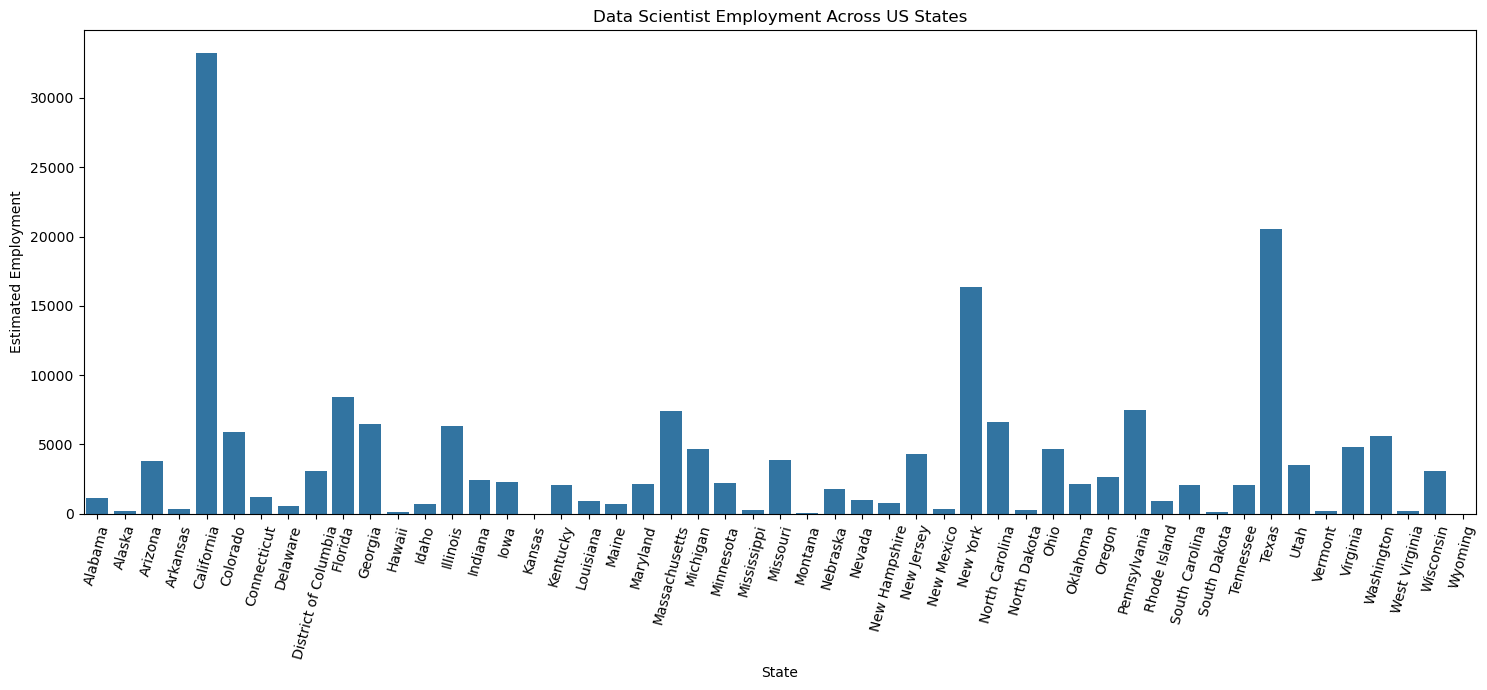

In [6]:
data_scientists = df[
    (df["OCC_TITLE"] == "Data Scientists") &
    (df["AREA_TYPE"].astype(str).str.strip() == "2") &
    (df["NAICS"].astype(str).str.strip().str.zfill(6) == "000000")
].copy()

data_scientists["TOT_EMP"] = pd.to_numeric(
    data_scientists["TOT_EMP"],
    errors="coerce"
)
plt.figure(figsize=(15, 7))

sns.barplot(
    data=data_scientists,
    x="AREA_TITLE",
    y="TOT_EMP"
)

plt.title("Data Scientist Employment Across US States")
plt.xlabel("State")
plt.ylabel("Estimated Employment")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()